# 08 - Data structure and consistency rules (Dashboard 10)

**Question:** which columns of the dataset are *derived from other columns* by a fixed rule, and how exactly?

A generator does not draw every column at random. Some columns are computed from others (a flag from the path, a count from the path, an account number from the bank). Those rules are the skeleton of the generator: if they hold with zero exceptions in 10,000,000 rows, they are certain, and every other dashboard can rely on them.

- Data: `feat` = `data/processed/transactions_features.parquet` (clean columns + features from `03_features`), queried with DuckDB through `src/eda.py` (UTC, in memory).
- Every rule is reported as **rows tested / exceptions found**. Where exceptions exist, they are examined, not hidden.
- Charts are saved to `reports/figures/` with the prefix `S`.

Run the cells top to bottom.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda
from src import settings as S

eda.connect()
eda.require_columns("feat", ["path_entries", "path_gaps", "path_first_differs", "path_last_differs",
                             "sender_country", "receiver_country"])
q = eda.q

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

EXPECTED_ROWS = 10_000_000
BIC = r"\d{4}[A-Z]{2}[A-Z0-9]{2}"          # 4 digits + 2-letter country + 2 characters
IBAN = r"_FAKE_[A-Z]{2}\d{20}"             # _FAKE_ + 2 letters + 20 digits

results = []  # one entry per rule: filled in as the notebook runs, shown in section 9


def record(rule, statement, unit, tested, exceptions):
    """Store one rule check and print it as 'exceptions in tested'."""
    tested, exceptions = int(tested), int(exceptions)
    results.append({"rule": rule, "statement": statement, "unit": unit, "tested": tested, "exceptions": exceptions})
    share = 100 * exceptions / tested if tested else float("nan")
    print(f"{rule}: {exceptions:,} exception{'' if exceptions == 1 else 's'} in {tested:,} {unit} tested ({share:.4f}%)  |  {statement}")

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 1.5.6 | time zone UTC


## 1. Sanity check
The row count must match the profiling report before any rule is tested.

In [2]:
check = q("""
    SELECT count(*)            AS n_rows,
           count(anomaly_type) AS anomalies,
           min(epoch_seconds)  AS first_payment_utc,
           max(epoch_seconds)  AS last_payment_utc
    FROM feat
""")
N = int(check.loc[0, "n_rows"])
assert N == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS:,} rows, found {N:,}"
check

,n_rows,anomalies,first_payment_utc,last_payment_utc
0,10000000,7006,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00


## 2. Hypotheses

H-S1 to H-S11 were written **before any query was run**, from reading the column descriptions in the case study and looking at sample rows. H-S12 to H-S14 were added after the first results (see the note under the table).

| ID | Hypothesis | Test |
|---|---|---|
| H-S1 | `continuity_qflag` is `N` exactly when the path contains a `...` gap | Compare the flag with `path_gaps > 0`, row by row |
| H-S2 | `participant_count` = number of real banks in the path (entries minus gaps) | Compare with `path_entries - path_gaps` |
| H-S3 | `Direct` exactly when there are 2 banks; `Indirect`/`Covered` only with 3 or more | Compare the type with `participant_count = 2` |
| H-S4 | A gap is never the first or last entry of a path | Paths starting or ending with `...` |
| H-S5 | Every BIC is 4 digits + 2 letters + 2 characters, in both BIC columns and in every path entry | Regular expression on all three columns |
| H-S6 | Each account belongs to exactly one bank | Distinct banks per account, sender side and receiver side |
| H-S7 | IBAN-shaped accounts embed the bank's country and its 4-digit code | Compare characters of the account with the BIC |
| H-S8 | Line 1 of the party details is `/` + the account | Compare line 1 with the account column |
| H-S9 | No line of the party details is longer than 35 characters | Longest line per row |
| H-S10 | Currency conversions never exceed banks minus 1 | Compare the two counts; cross-table |
| H-S11 | The tokens text has the same number of lines as the details text | Count line breaks in both |
| H-S12 | *(added)* The 2 check digits of an IBAN-shaped account are valid (ISO 13616 mod-97 test) | Recompute the checksum |
| H-S13 | *(added)* Each account always has the same party type (B or C) | Distinct types per account, and across the two sides |
| H-S14 | *(added)* Hard value limits: amounts have at most 2 decimals and are at least 0.01; no fully identical rows | Raw text of the amount; identical-row search |

**How the hypotheses changed.** H-S7 held so cleanly that it raised a follow-up: if the generator builds IBANs from the bank, does it also compute real check digits (H-S12)? H-S6 held for senders but not for receivers, which led to asking whether the party type is stable too (H-S13). H-S14 came from the profiling report, which counted one identical row.

## 3. Path, flags and counts (H-S1 to H-S5)

`bic8_path` is the list of banks a payment passed through, separated by `;`, where `...` marks a gap. Three other columns describe the same route: `continuity_qflag`, `participant_count` and `transaction_type_code`. If they are derived from the path, they can never disagree with it.

In [3]:
a = q(f"""
    SELECT count(*)                                                                    AS n,
           sum((continuity_qflag <> (path_gaps = 0))::INT)                             AS s1_exceptions,
           sum((participant_count <> path_entries - path_gaps)::INT)                   AS s2_exceptions,
           sum(((transaction_type_code = 'Direct') <> (participant_count = 2))::INT)   AS s3_exceptions,
           sum((bic8_path LIKE '...%' OR bic8_path LIKE '%...')::INT)                  AS s4_exceptions,
           sum((NOT regexp_full_match(ordering_bic8, '{BIC}')
                OR NOT regexp_full_match(beneficiary_bic8, '{BIC}')
                OR NOT regexp_full_match(bic8_path, '({BIC}|\\.\\.\\.)(;({BIC}|\\.\\.\\.))*'))::INT) AS s5_exceptions,
           sum((path_gaps > 0)::INT)                                                   AS rows_with_gap,
           max(path_gaps)                                                              AS max_gaps_in_one_path,
           max(path_entries)                                                           AS max_entries,
           max(participant_count)                                                      AS max_banks
    FROM feat
""").iloc[0]
record("H-S1", "continuity_qflag = N exactly when the path has a gap", "rows", a.n, a.s1_exceptions)
record("H-S2", "participant_count = path entries - gaps", "rows", a.n, a.s2_exceptions)
record("H-S3", "Direct exactly when 2 banks", "rows", a.n, a.s3_exceptions)
record("H-S4", "a gap is never the first or last path entry", "rows", a.n, a.s4_exceptions)
record("H-S5", "every BIC is 4 digits + 2 letters + 2 characters", "rows", a.n, a.s5_exceptions)
print(f"\nRows with at least one gap: {int(a.rows_with_gap):,} ({100 * a.rows_with_gap / a.n:.2f}%) | "
      f"most gaps in one path: {int(a.max_gaps_in_one_path)} | longest path: {int(a.max_entries)} entries | most banks: {int(a.max_banks)}")

H-S1: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  continuity_qflag = N exactly when the path has a gap
H-S2: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  participant_count = path entries - gaps
H-S3: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  Direct exactly when 2 banks
H-S4: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  a gap is never the first or last path entry
H-S5: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  every BIC is 4 digits + 2 letters + 2 characters

Rows with at least one gap: 767,204 (7.67%) | most gaps in one path: 6 | longest path: 24 entries | most banks: 22


**Control check.** A rule that holds overall could still hide a group where it fails and another where it compensates. The same five checks, split by transaction type and by normal vs anomaly rows:

In [4]:
q(f"""
    SELECT transaction_type_code                                                      AS type,
           CASE WHEN anomaly_type IS NULL THEN 'normal' ELSE 'anomaly' END             AS label,
           count(*)                                                                    AS n,
           min(participant_count)                                                      AS min_banks,
           max(participant_count)                                                      AS max_banks,
           round(100 * avg((path_gaps > 0)::INT), 2)                                   AS pct_rows_with_gap,
           sum((continuity_qflag <> (path_gaps = 0))::INT)
             + sum((participant_count <> path_entries - path_gaps)::INT)
             + sum(((transaction_type_code = 'Direct') <> (participant_count = 2))::INT)
             + sum((bic8_path LIKE '...%' OR bic8_path LIKE '%...')::INT)             AS exceptions_s1_to_s4
    FROM feat
    GROUP BY 1, 2
    ORDER BY 1, 2 DESC
""")

,type,label,n,min_banks,max_banks,pct_rows_with_gap,exceptions_s1_to_s4
0,Covered,normal,415815,3,15,12.32,0.0
1,Covered,anomaly,147,3,10,18.37,0.0
2,Direct,normal,6318885,2,2,4.99,0.0
3,Direct,anomaly,4395,2,2,5.10,0.0
4,Indirect,normal,3258294,3,22,12.29,0.0
5,Indirect,anomaly,2464,3,11,11.77,0.0


**Result: H-S1 to H-S5 all held.** The flag, the count and the Direct label are computed from the path, in every transaction type and for anomalies as well as normal rows. Gaps are placeholders between two known banks and are not counted as banks.

## 4. Currency conversions are bounded by the route (H-S10)

If a conversion happens when one bank hands the payment to the next, a route with *k* banks has *k - 1* hand-offs and can hold at most *k - 1* conversions.

In [5]:
conv = q("""
    SELECT participant_count AS banks, currency_conversion_count AS conversions, count(*) AS n
    FROM feat GROUP BY 1, 2
""")
over = int(conv.loc[conv.conversions > conv.banks - 1, "n"].sum())
record("H-S10", "currency conversions <= banks - 1", "rows", conv.n.sum(), over)
at_max = int(conv.loc[conv.conversions == conv.banks - 1, "n"].sum())
print(f"Rows where conversions are exactly banks - 1 (the maximum possible): {at_max:,} ({100 * at_max / conv.n.sum():.2f}%)")
(conv.groupby("banks").agg(rows=("n", "sum"), min_conversions=("conversions", "min"), max_conversions=("conversions", "max"))
     .assign(max_allowed=lambda d: d.index - 1))

H-S10: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  currency conversions <= banks - 1
Rows where conversions are exactly banks - 1 (the maximum possible): 7,864,805 (78.65%)


,rows,min_conversions,max_conversions,max_allowed
banks,,,,
2,6323280,0,1,1
3,2324319,0,2,2
4,855386,0,3,3
5,314014,0,4,4
6,115701,0,5,5
7,42622,0,6,6
8,15481,0,7,7
9,5758,2,8,8
10,2205,1,9,9


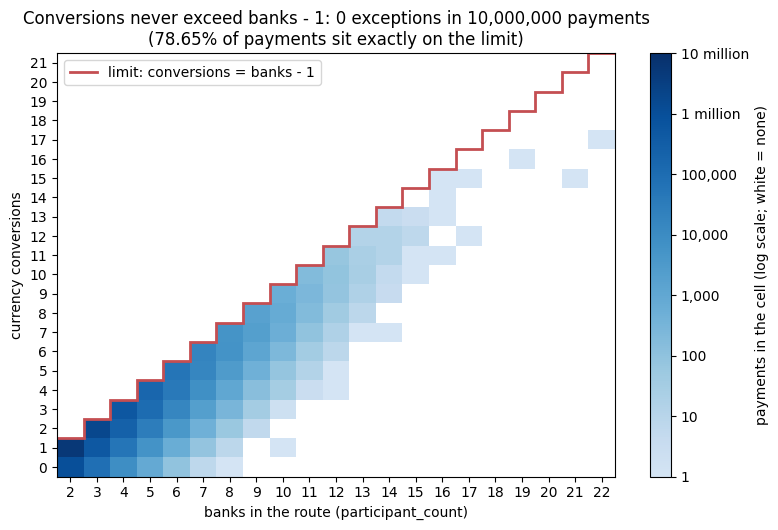

In [6]:
grid = conv.pivot(index="conversions", columns="banks", values="n")
banks_axis = np.arange(int(conv.banks.min()), int(conv.banks.max()) + 1)
conv_axis = np.arange(0, int(conv.banks.max()))
grid = grid.reindex(index=conv_axis, columns=banks_axis)

fig, ax = plt.subplots(figsize=(9, 5.5))
mesh = ax.pcolormesh(banks_axis, conv_axis, np.log10(grid.to_numpy(dtype=float)), cmap="Blues", shading="nearest",
                     vmin=-1.5, vmax=7)   # vmin below 0 so that a cell holding a single payment is still visibly blue
edges = np.append(banks_axis, banks_axis[-1] + 1) - 0.5   # left edge of each column of cells, plus the right end
ax.stairs(banks_axis - 0.5, edges, baseline=None, color="#C44E52", lw=2, label="limit: conversions = banks - 1")
ax.set_xlabel("banks in the route (participant_count)")
ax.set_ylabel("currency conversions")
ax.set_xticks(banks_axis)
ax.set_yticks(conv_axis)
ax.legend(loc="upper left")
cbar = fig.colorbar(mesh, ax=ax, ticks=range(0, 8))
cbar.ax.set_yticklabels(["1", "10", "100", "1,000", "10,000", "100,000", "1 million", "10 million"])
cbar.ax.set_ylim(0, 7)
cbar.set_label("payments in the cell (log scale; white = none)")
ax.set_title(f"Conversions never exceed banks - 1: {over:,} exceptions in {int(conv.n.sum()):,} payments\n"
             f"({100 * at_max / conv.n.sum():.2f}% of payments sit exactly on the limit)")
eda.save(fig, "S1_conversions_vs_banks")
plt.show()

**Result: H-S10 held.** The table shows the limit is reached at every route length from 2 to 14 banks, which covers all but 21 payments; the six longer route lengths have 12 payments or fewer each. So it is a real ceiling, not an accident of small numbers. How the number of conversions is chosen *below* that ceiling belongs to the currency dashboard.

## 5. Accounts, banks and party types (H-S6, H-S13)

Is an account number tied to one bank and one party type, the way a real account is?

In [7]:
def account_side(side):
    return q(f"""
        WITH a AS (
            SELECT {side}_account                        AS account,
                   regexp_full_match({side}_account, '{IBAN}') AS iban_shaped,
                   count(DISTINCT {side}_bic8)           AS n_banks,
                   count(DISTINCT {side}_type)           AS n_types,
                   count(*)                              AS n_rows
            FROM feat GROUP BY 1, 2
        )
        SELECT '{side}'                                  AS side,
               CASE WHEN iban_shaped THEN 'IBAN-shaped' ELSE 'other format' END AS account_format,
               count(*)                                  AS accounts,
               sum(n_rows)                               AS payments,
               sum((n_banks > 1)::INT)                   AS accounts_with_several_banks,
               coalesce(sum(n_rows) FILTER (WHERE n_banks > 1), 0) AS payments_of_those_accounts,
               max(n_banks)                              AS most_banks_for_one_account,
               sum((n_types > 1)::INT)                   AS accounts_with_several_types
        FROM a GROUP BY 1, 2 ORDER BY 2
    """)

acc = pd.concat([account_side("ordering"), account_side("beneficiary")], ignore_index=True)
for side in ["ordering", "beneficiary"]:
    d = acc[acc.side == side]
    record("H-S6", f"each {side} account belongs to one bank", "accounts", d.accounts.sum(), d.accounts_with_several_banks.sum())
    record("H-S13", f"each {side} account has one party type", "accounts", d.accounts.sum(), d.accounts_with_several_types.sum())
acc

H-S6: 0 exceptions in 391,132 accounts tested (0.0000%)  |  each ordering account belongs to one bank
H-S13: 0 exceptions in 391,132 accounts tested (0.0000%)  |  each ordering account has one party type
H-S6: 61,606 exceptions in 2,590,877 accounts tested (2.3778%)  |  each beneficiary account belongs to one bank
H-S13: 0 exceptions in 2,590,877 accounts tested (0.0000%)  |  each beneficiary account has one party type


,side,account_format,accounts,payments,accounts_with_several_banks,payments_of_those_accounts,most_banks_for_one_account,accounts_with_several_types
0,ordering,IBAN-shaped,111194,5442631.0,0.0,0.0,1,0.0
1,ordering,other format,279938,4557369.0,0.0,0.0,1,0.0
2,beneficiary,IBAN-shaped,1355669,5405035.0,0.0,0.0,1,0.0
3,beneficiary,other format,1235208,4594965.0,61606.0,588770.0,8,0.0


H-S6 holds for every sender account, and for every IBAN-shaped receiver account, but **not** for receiver accounts in other formats. Two possible explanations to test:

1. *Noise:* the 5% last-bank mismatch found in notebook 02 (path end is not `beneficiary_bic8`) might also scramble the receiver bank. If so, the affected accounts should show a much higher mismatch rate.
2. *Structure:* the account string is simply reused at several banks.

In [8]:
q(f"""
    WITH a AS (SELECT beneficiary_account, count(DISTINCT beneficiary_bic8) AS n_banks FROM feat GROUP BY 1)
    SELECT CASE WHEN regexp_full_match(beneficiary_account, '{IBAN}') THEN 'IBAN-shaped' ELSE 'other format' END AS account_format,
           CASE WHEN n_banks > 1 THEN 'several banks' ELSE 'one bank' END              AS receiver_account_seen_at,
           count(*)                                                                    AS payments,
           round(100 * avg(path_last_differs::INT), 2)                                 AS pct_last_bank_in_path_differs
    FROM feat JOIN a USING (beneficiary_account)
    GROUP BY 1, 2 ORDER BY 1, 2
""")

,account_format,receiver_account_seen_at,payments,pct_last_bank_in_path_differs
0,IBAN-shaped,one bank,5405035,4.99
1,other format,one bank,4006195,4.96
2,other format,several banks,588770,5.24


In [9]:
# How are the payments of a several-bank account spread over its banks?
spread = q(f"""
    WITH ab AS (
        SELECT beneficiary_account AS account, beneficiary_bic8 AS bic, count(*) AS n
        FROM feat WHERE NOT regexp_full_match(beneficiary_account, '{IBAN}') GROUP BY 1, 2
    ), s AS (
        SELECT account, count(*) AS n_banks, max(n) * 1.0 / sum(n) AS share_at_main_bank, sum(n) AS payments
        FROM ab GROUP BY 1 HAVING count(*) > 1
    )
    SELECT n_banks, count(*) AS accounts, sum(payments) AS payments,
           round(median(share_at_main_bank), 3) AS median_share_at_main_bank
    FROM s GROUP BY 1 ORDER BY 1
""")
spread

,n_banks,accounts,payments,median_share_at_main_bank
0,2,52518,436013.0,0.500
1,3,7342,106582.0,0.500
2,4,1424,37884.0,0.500
3,5,252,6664.0,0.500
4,6,57,1268.0,0.444
5,7,12,343.0,0.449
6,8,1,16.0,0.313


The mismatch rate is about 5% in every group, so explanation 1 (noise) is **ruled out**. Payments of a several-bank account are split fairly evenly between its banks (a noise process would leave one dominant bank and a few stray rows), which fits explanation 2: on the receiver side, a non-IBAN account string is not unique to one bank.

**Party type across the two sides.** Within one side an account never changes type. But the same account string can appear as a sender in one payment and as a receiver in another:

In [10]:
both = q("""
    WITH o AS (SELECT DISTINCT ordering_account    AS account, ordering_bic8    AS o_bic, ordering_type    AS o_type FROM feat),
         b AS (SELECT DISTINCT beneficiary_account AS account, beneficiary_bic8 AS b_bic, beneficiary_type AS b_type FROM feat)
    SELECT count(*)                          AS account_bank_pairs,
           count(DISTINCT account)           AS accounts_on_both_sides,
           sum((o_bic <> b_bic)::INT)        AS pairs_bank_differs,
           sum((o_type <> b_type)::INT)      AS pairs_type_differs,
           avg((o_type = 'B')::INT)          AS share_sender_business,
           avg((b_type = 'B')::INT)          AS share_receiver_business
    FROM o JOIN b USING (account)
""").iloc[0]
p_o, p_b = both.share_sender_business, both.share_receiver_business
expected_if_independent = p_o * (1 - p_b) + (1 - p_o) * p_b
record("H-S13", "an account has the same party type as sender and as receiver", "account pairs",
       both.account_bank_pairs, both.pairs_type_differs)
print(f"Accounts seen on both sides: {int(both.accounts_on_both_sides):,}")
print(f"  bank differs between the two sides : {int(both.pairs_bank_differs):,} of {int(both.account_bank_pairs):,} pairs "
      f"({100 * both.pairs_bank_differs / both.account_bank_pairs:.2f}%)")
print(f"  type differs between the two sides : {int(both.pairs_type_differs):,} of {int(both.account_bank_pairs):,} pairs "
      f"({100 * both.pairs_type_differs / both.account_bank_pairs:.2f}%)")
print(f"  type would differ in {100 * expected_if_independent:.2f}% of pairs if the two types were drawn independently "
      f"(sender is a business in {100 * p_o:.1f}%, receiver in {100 * p_b:.1f}%)")

H-S13: 128,261 exceptions in 254,085 account pairs tested (50.4796%)  |  an account has the same party type as sender and as receiver
Accounts seen on both sides: 253,120
  bank differs between the two sides : 1,051 of 254,085 pairs (0.41%)
  type differs between the two sides : 128,261 of 254,085 pairs (50.48%)
  type would differ in 50.15% of pairs if the two types were drawn independently (sender is a business in 50.4%, receiver in 29.5%)


**Result.** H-S6 held for senders and for IBAN-shaped receivers, and **failed** for non-IBAN receivers. H-S13 held within each side and **failed** across sides: the observed disagreement is compared above with what two independent draws would give. The two figures are within half a percentage point of each other, so the party type behaves as if it were attached to the *role in a payment* (sender list, receiver list), not to the account itself.

## 6. IBAN-shaped accounts are built from the bank (H-S7, H-S12)

Sample rows suggested a layout: `_FAKE_` + country (2 letters) + 2 digits + the bank's 4-digit code + more digits. For example `_FAKE_TR53002400000000890222` belongs to bank `0024TRI0`.

In [11]:
def iban_side(side, hop_sql):
    return q(f"""
        WITH s AS (
            SELECT {side}_account AS a, {side}_bic8 AS bic, {hop_sql} AS path_bank
            FROM feat WHERE regexp_full_match({side}_account, '{IBAN}')
        )
        SELECT '{side}'                                                                   AS side,
               count(*)                                                                    AS iban_rows,
               sum((substr(a, 7, 2) <> substr(bic, 5, 2))::INT)                            AS country_differs_from_bic,
               sum((substr(a, 11, 4) <> substr(bic, 1, 4))::INT)                           AS bank_code_differs_from_bic,
               sum((substr(a, 7, 2) <> substr(bic, 5, 2)
                    OR substr(a, 11, 4) <> substr(bic, 1, 4))::INT)                        AS differs_from_bic,
               sum((substr(a, 15, 8) <> '00000000')::INT)                                  AS digits_15_to_22_not_zero,
               sum((substr(a, 7, 2) <> substr(path_bank, 5, 2)
                    OR substr(a, 11, 4) <> substr(path_bank, 1, 4))::INT)                  AS differs_from_path_end_bank
        FROM s
    """)

iban = pd.concat([iban_side("ordering", "split_part(bic8_path, ';', 1)"),
                  iban_side("beneficiary", "string_split(bic8_path, ';')[-1]")], ignore_index=True)
iban["pct_of_all_rows"] = (100 * iban.iban_rows / N).round(2)
for r in iban.itertuples():
    record("H-S7", f"{r.side} IBAN embeds the country and 4-digit code of {r.side}_bic8", "IBAN rows",
           r.iban_rows, r.differs_from_bic)
iban

H-S7: 0 exceptions in 5,442,631 IBAN rows tested (0.0000%)  |  ordering IBAN embeds the country and 4-digit code of ordering_bic8
H-S7: 0 exceptions in 5,405,035 IBAN rows tested (0.0000%)  |  beneficiary IBAN embeds the country and 4-digit code of beneficiary_bic8


,side,iban_rows,country_differs_from_bic,bank_code_differs_from_bic,differs_from_bic,digits_15_to_22_not_zero,differs_from_path_end_bank,pct_of_all_rows
0,ordering,5442631,0.0,0.0,0.0,0.0,270934.0,54.43
1,beneficiary,5405035,0.0,0.0,0.0,0.0,269878.0,54.05


The account agrees with the **BIC column** in every row, but with the **bank at the end of the path** in only about 95%. So the account is always built from the party's bank in the BIC column, never from the path. Notebook 02 found that the path end differs from the BIC column in 5% of rows; which of the two banks the route was built for is tested in notebook `09_routing` (it is the path end).

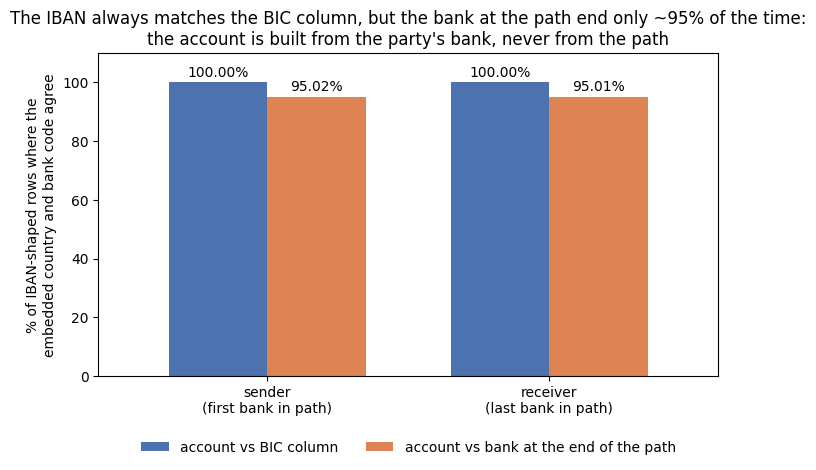

In [12]:
d = iban.set_index("side")
agree = pd.DataFrame({
    "account vs BIC column": 100 - 100 * d.differs_from_bic / d.iban_rows,
    "account vs bank at the end of the path": 100 - 100 * d.differs_from_path_end_bank / d.iban_rows,
}).rename(index={"ordering": "sender\n(first bank in path)", "beneficiary": "receiver\n(last bank in path)"})

fig, ax = plt.subplots(figsize=(8, 4.2))
agree.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"], rot=0, width=0.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=2)
ax.set_ylim(0, 110)
ax.set_xlabel("")
ax.set_ylabel("% of IBAN-shaped rows where the\nembedded country and bank code agree")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
ax.set_title("The IBAN always matches the BIC column, but the bank at the path end only ~95% of the time:\n"
             "the account is built from the party's bank, never from the path")
eda.save(fig, "S2_iban_bank_link")
plt.show()

**Check digits (H-S12).** A real IBAN carries 2 check digits such that the rearranged number leaves remainder 1 when divided by 97 (ISO 13616). If the generator computed them, 100% would pass; if it drew 2 random digits, about 1 in 97 (1.03%) would pass by chance.

In [13]:
def checksum_side(side):
    return q(f"""
        WITH a AS (SELECT DISTINCT {side}_account AS a FROM feat WHERE regexp_full_match({side}_account, '{IBAN}')),
             m AS (
                 -- digits 11-28, then the two country letters as numbers (A=10 ... Z=35), then the 2 check digits
                 SELECT CAST(substr(a, 11, 18) || CAST(ascii(substr(a, 7, 1)) - 55 AS VARCHAR)
                             || CAST(ascii(substr(a, 8, 1)) - 55 AS VARCHAR) || substr(a, 9, 2) AS HUGEINT) % 97 AS remainder
                 FROM a
             )
        SELECT '{side}' AS side, count(*) AS distinct_iban_accounts, sum((remainder = 1)::INT) AS valid_check_digits FROM m
    """)

chk = pd.concat([checksum_side("ordering"), checksum_side("beneficiary")], ignore_index=True)
chk["pct_valid"] = (100 * chk.valid_check_digits / chk.distinct_iban_accounts).round(3)
chk["pct_valid_if_random"] = round(100 / 97, 3)
for r in chk.itertuples():
    record("H-S12", f"{r.side} IBAN check digits are valid (mod 97)", "distinct IBAN accounts",
           r.distinct_iban_accounts, r.distinct_iban_accounts - r.valid_check_digits)
chk

H-S12: 110,100 exceptions in 111,194 distinct IBAN accounts tested (99.0161%)  |  ordering IBAN check digits are valid (mod 97)
H-S12: 1,341,656 exceptions in 1,355,669 distinct IBAN accounts tested (98.9663%)  |  beneficiary IBAN check digits are valid (mod 97)


,side,distinct_iban_accounts,valid_check_digits,pct_valid,pct_valid_if_random
0,ordering,111194,1094.0,0.984,1.031
1,beneficiary,1355669,14013.0,1.034,1.031


**Result: H-S7 held, H-S12 was rejected.** The country, the bank code and a run of 8 zeros are fixed by rule; the check digits pass the real test at the chance rate, so they are 2 random digits. The account number proper is the last 6 digits.

## 7. Party details: account line and line length (H-S8, H-S9, H-S11)

`ordering_details` and `beneficiary_details` are free text with embedded line breaks. Do they follow fixed layout rules?

In [14]:
def line1_side(side):
    return q(f"""
        WITH s AS (
            SELECT substr({side}_account, 7) AS account_text,          -- the account without the _FAKE_ prefix
                   split_part({side}_details, chr(10), 1) AS line1,
                   {side}_type AS party_type
            FROM feat
        )
        SELECT '{side}' AS side,
               CASE WHEN line1 = '/'  || account_text THEN '1. line 1 = /account'
                    WHEN line1 = '//' || account_text THEN '2. line 1 = //account'
                    WHEN NOT starts_with(line1, '/')  THEN '3. no account line'
                    ELSE '4. anything else' END AS layout,
               count(*) AS n_rows,
               sum((party_type = 'B')::INT) AS business_rows,
               sum((party_type = 'C')::INT) AS consumer_rows
        FROM s GROUP BY 1, 2 ORDER BY 2
    """)

line1 = pd.concat([line1_side("ordering"), line1_side("beneficiary")], ignore_index=True)
line1["pct_of_side"] = (100 * line1.n_rows / N).round(2)
tot = line1.groupby("side")[["business_rows", "consumer_rows"]].transform("sum")
line1["pct_within_business"] = (100 * line1.business_rows / tot.business_rows).round(2)
line1["pct_within_consumer"] = (100 * line1.consumer_rows / tot.consumer_rows).round(2)
for side in ["ordering", "beneficiary"]:
    d = line1[line1.side == side]
    record("H-S8", f"{side}: line 1 is exactly /account", "rows", N, N - d.loc[d.layout.str.startswith("1."), "n_rows"].sum())
    record("H-S8 refined", f"{side}: line 1 is /account or //account, or there is no account line", "rows",
           N, d.loc[d.layout.str.startswith("4."), "n_rows"].sum())
line1.drop(columns=["business_rows", "consumer_rows"])

H-S8: 1,356,368 exceptions in 10,000,000 rows tested (13.5637%)  |  ordering: line 1 is exactly /account
H-S8 refined: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  ordering: line 1 is /account or //account, or there is no account line
H-S8: 1,468,742 exceptions in 10,000,000 rows tested (14.6874%)  |  beneficiary: line 1 is exactly /account
H-S8 refined: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  beneficiary: line 1 is /account or //account, or there is no account line


,side,layout,n_rows,pct_of_side,pct_within_business,pct_within_consumer
0,ordering,1. line 1 = /account,8643632,86.44,86.65,85.64
1,ordering,2. line 1 = //account,793258,7.93,7.93,7.96
2,ordering,3. no account line,563110,5.63,5.42,6.40
3,beneficiary,1. line 1 = /account,8531258,85.31,85.30,85.32
4,beneficiary,2. line 1 = //account,859360,8.59,8.59,8.60
5,beneficiary,3. no account line,609382,6.09,6.12,6.08


H-S8 as first written holds for most rows only. The refined rule covers every row: the account line is `/account` or `//account`, copied character for character including spaces, or it is left out. The split by party type (last two columns) is the control: if the layout choice does not depend on B or C, the percentages match.

**Line length (H-S9).**

In [15]:
def long_lines_side(side):
    return q(f"""
        WITH l AS (
            SELECT unnest(string_split({side}_details, chr(10))) AS line
            FROM feat WHERE regexp_matches({side}_details, '[^\\n]{{36,}}')
        )
        SELECT '{side}' AS side,
               CASE WHEN regexp_matches(line, '^[0-9]/') THEN 'numbered line (1/ 2/ 3/)' ELSE 'other line' END AS line_kind,
               count(*) AS lines_over_35, min(length(line)) AS shortest, max(length(line)) AS longest,
               min(line) AS example
        FROM l WHERE length(line) > 35 GROUP BY 1, 2
    """)

def length_side(side):
    return q(f"""
        SELECT '{side}' AS side,
               sum(regexp_matches({side}_details, '[^\\n]{{36,}}')::INT)       AS rows_with_line_over_35,
               sum(regexp_matches({side}_details, '(^|\\n)[0-9]/')::INT)       AS rows_with_numbered_lines,
               sum(regexp_matches({side}_details, '(^|\\n)[^\\n]{{35}}(\\n|$)')::INT) AS rows_with_line_of_exactly_35
        FROM feat
    """)

lengths = pd.concat([length_side("ordering"), length_side("beneficiary")], ignore_index=True)
for r in lengths.itertuples():
    record("H-S9", f"{r.side}: no details line is longer than 35 characters", "rows", N, r.rows_with_line_over_35)
display(lengths)
long_lines = pd.concat([long_lines_side("ordering"), long_lines_side("beneficiary")], ignore_index=True)
long_lines

H-S9: 3,053 exceptions in 10,000,000 rows tested (0.0305%)  |  ordering: no details line is longer than 35 characters
H-S9: 7,318 exceptions in 10,000,000 rows tested (0.0732%)  |  beneficiary: no details line is longer than 35 characters


,side,rows_with_line_over_35,rows_with_numbered_lines,rows_with_line_of_exactly_35
0,ordering,3053.0,1606319.0,5277972.0
1,beneficiary,7318.0,1504471.0,5373013.0


,side,line_kind,lines_over_35,shortest,longest,example
0,ordering,other line,1,43,43,"S, PROVIDENCIA Y SANTA CATALINA 9-12 130429"
1,ordering,numbered line (1/ 2/ 3/),3052,36,58,"1/, BAZOWNTS` EW MELIK`-BARKHOWDARYAN BBE"
2,beneficiary,numbered line (1/ 2/ 3/),7314,36,58,"1/AMYAN, ZOWRABYAN EW GOWLAK`SYAN SPE"
3,beneficiary,other line,5,36,43,AN BRETANA E IRLANDA DEL NORTE 94394


**Tokens vs details line count (H-S11).**

In [16]:
def token_lines_side(side):
    return q(f"""
        WITH t AS (
            SELECT len(string_split({side}_details, chr(10))) - len(string_split({side}_tokens, chr(10))) AS extra_lines_in_details,
                   len(regexp_extract_all({side}_tokens, '<line_break:'))                                AS line_break_tokens
            FROM feat
        )
        SELECT '{side}' AS side, extra_lines_in_details, line_break_tokens, count(*) AS n_rows
        FROM t GROUP BY 1, 2, 3
    """)

tok = pd.concat([token_lines_side("ordering"), token_lines_side("beneficiary")], ignore_index=True)
for side in ["ordering", "beneficiary"]:
    d = tok[tok.side == side]
    record("H-S11", f"{side}: tokens and details have the same number of lines", "rows",
           d.n_rows.sum(), d.loc[d.extra_lines_in_details != 0, "n_rows"].sum())
    same_as_tokens = d.loc[d.extra_lines_in_details == d.line_break_tokens, "n_rows"].sum()
    print(f"  {side}: extra lines in details = number of <line_break> tokens in {100 * same_as_tokens / d.n_rows.sum():.2f}% of rows")
tok[tok.side == "ordering"].pivot(index="extra_lines_in_details", columns="line_break_tokens", values="n_rows").fillna(0).astype(int)

H-S11: 6,344,427 exceptions in 10,000,000 rows tested (63.4443%)  |  ordering: tokens and details have the same number of lines
  ordering: extra lines in details = number of <line_break> tokens in 77.34% of rows
H-S11: 6,528,322 exceptions in 10,000,000 rows tested (65.2832%)  |  beneficiary: tokens and details have the same number of lines
  beneficiary: extra lines in details = number of <line_break> tokens in 75.66% of rows


line_break_tokens,0,1,2,3,4
extra_lines_in_details,,,,,
-1,16655,0,0,0,0
0,3548306,107267,0,0,0
1,1694577,3823725,24609,0,0
2,82451,326618,351586,66,0
3,437,3801,9184,10675,0
4,0,1,7,21,14


**Result.** H-S9 held with rare exceptions: free-format lines are wrapped at 35 characters, and almost every longer line is a numbered line (`1/`, `2/`, `3/`), which is not wrapped (see the `line_kind` table; the handful of other lines is unexplained). H-S11 was **rejected**: the tokens describe a wrapped line as one line plus a `<line_break:N>` marker, so the details usually have more lines. Counting those markers explains most, but not all, of the difference (printed above); the exact wrapping rule is left to the party details dashboard.

## 8. Hard value limits and identical rows (H-S14)

In [17]:
limits = q("""
    SELECT min(usd_amount) AS min_amount, max(usd_amount) AS max_amount,
           min(total_duration) AS min_duration_s, max(total_duration) AS max_duration_s,
           min(participant_count) AS min_banks, min(currency_conversion_count) AS min_conversions,
           min(epoch_seconds) AS first_payment_utc, max(epoch_seconds) AS last_payment_utc
    FROM feat
""")
display(limits)

if S.RAW_PARQUET.exists():   # the amount exactly as written in the CSV, before conversion to a number
    dec = q(f"""
        SELECT count(*) AS n,
               sum((NOT regexp_full_match(usd_amount, '[0-9]+(\\.[0-9]{{1,2}})?'))::INT) AS not_plain_number_with_max_2_decimals,
               sum((CAST(usd_amount AS DOUBLE) < 0.01)::INT)                              AS below_one_cent
        FROM read_parquet('{S.RAW_PARQUET.as_posix()}')
    """).iloc[0]
    record("H-S14", "usd_amount is a plain number with at most 2 decimals, at least 0.01", "rows",
           dec.n, dec.not_plain_number_with_max_2_decimals + dec.below_one_cent)
else:
    print("Raw Parquet file not found - decimal check skipped (run 01_preprocessing to create it)")

,min_amount,max_amount,min_duration_s,max_duration_s,min_banks,min_conversions,first_payment_utc,last_payment_utc
0,0.01,1.566413e+10,2,21649,2,0,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00


H-S14: 0 exceptions in 10,000,000 rows tested (0.0000%)  |  usd_amount is a plain number with at most 2 decimals, at least 0.01


In [18]:
# Fully identical rows: find candidates on four columns, then compare every column of the candidates
dupes = q("""
    WITH k AS (
        SELECT epoch_seconds, ordering_account, beneficiary_account, usd_amount
        FROM tx GROUP BY ALL HAVING count(*) > 1
    )
    SELECT tx.* FROM tx JOIN k USING (epoch_seconds, ordering_account, beneficiary_account, usd_amount)
""")
identical_extra_rows = int(dupes.duplicated(keep="first").sum())
record("H-S14", "no two rows are identical in every column", "rows", N, identical_extra_rows)
print(f"Rows sharing timestamp, both accounts and amount: {len(dupes)} | of which fully identical copies: {identical_extra_rows}")
dupes[["epoch_seconds", "usd_amount", "currency_code", "bic8_path", "total_duration", "ordering_type", "beneficiary_type", "anomaly_type"]]

H-S14: 1 exception in 10,000,000 rows tested (0.0000%)  |  no two rows are identical in every column
Rows sharing timestamp, both accounts and amount: 2 | of which fully identical copies: 1


,epoch_seconds,usd_amount,currency_code,bic8_path,total_duration,ordering_type,beneficiary_type,anomaly_type
0,2023-06-26 08:59:32+00:00,32.36,EUR,0198DEF0;0666US30;0006PLP0;0061SAR0;0181US30,78,C,C,DUPLICATE_PAYMENT
1,2023-06-26 08:59:32+00:00,32.36,EUR,0198DEF0;0666US30;0006PLP0;0061SAR0;0181US30,78,C,C,DUPLICATE_PAYMENT


**Result.** Amounts are always written in whole cents and never below 0.01. Identical rows are shown above with their label, which says whether the copy is a data problem or part of an anomaly the generator created on purpose.

## 9. Scoreboard: every rule, rows tested, exceptions

In [19]:
board = pd.DataFrame(results)
board["pct_following_rule"] = 100 - 100 * board.exceptions / board.tested
board["verdict"] = np.select(
    [board.exceptions == 0, board.pct_following_rule >= 99, board.pct_following_rule >= 50],
    ["holds, 0 exceptions", "holds with rare exceptions", "partly holds"], default="rejected")
board.to_csv(S.PROFILE_DIR / "consistency_rules.csv", index=False)
print(f"{(board.exceptions == 0).sum()} of {len(board)} checks have zero exceptions")
board[["rule", "statement", "unit", "tested", "exceptions", "pct_following_rule", "verdict"]]

14 of 25 checks have zero exceptions


,rule,statement,unit,tested,exceptions,pct_following_rule,verdict
0,H-S1,continuity_qflag = N exactly when the path has a gap,rows,10000000,0,100.000000,"holds, 0 exceptions"
1,H-S2,participant_count = path entries - gaps,rows,10000000,0,100.000000,"holds, 0 exceptions"
2,H-S3,Direct exactly when 2 banks,rows,10000000,0,100.000000,"holds, 0 exceptions"
3,H-S4,a gap is never the first or last path entry,rows,10000000,0,100.000000,"holds, 0 exceptions"
4,H-S5,every BIC is 4 digits + 2 letters + 2 characters,rows,10000000,0,100.000000,"holds, 0 exceptions"
5,H-S10,currency conversions <= banks - 1,rows,10000000,0,100.000000,"holds, 0 exceptions"
6,H-S6,each ordering account belongs to one bank,accounts,391132,0,100.000000,"holds, 0 exceptions"
7,H-S13,each ordering account has one party type,accounts,391132,0,100.000000,"holds, 0 exceptions"
8,H-S6,each beneficiary account belongs to one bank,accounts,2590877,61606,97.622195,partly holds
9,H-S13,each beneficiary account has one party type,accounts,2590877,0,100.000000,"holds, 0 exceptions"


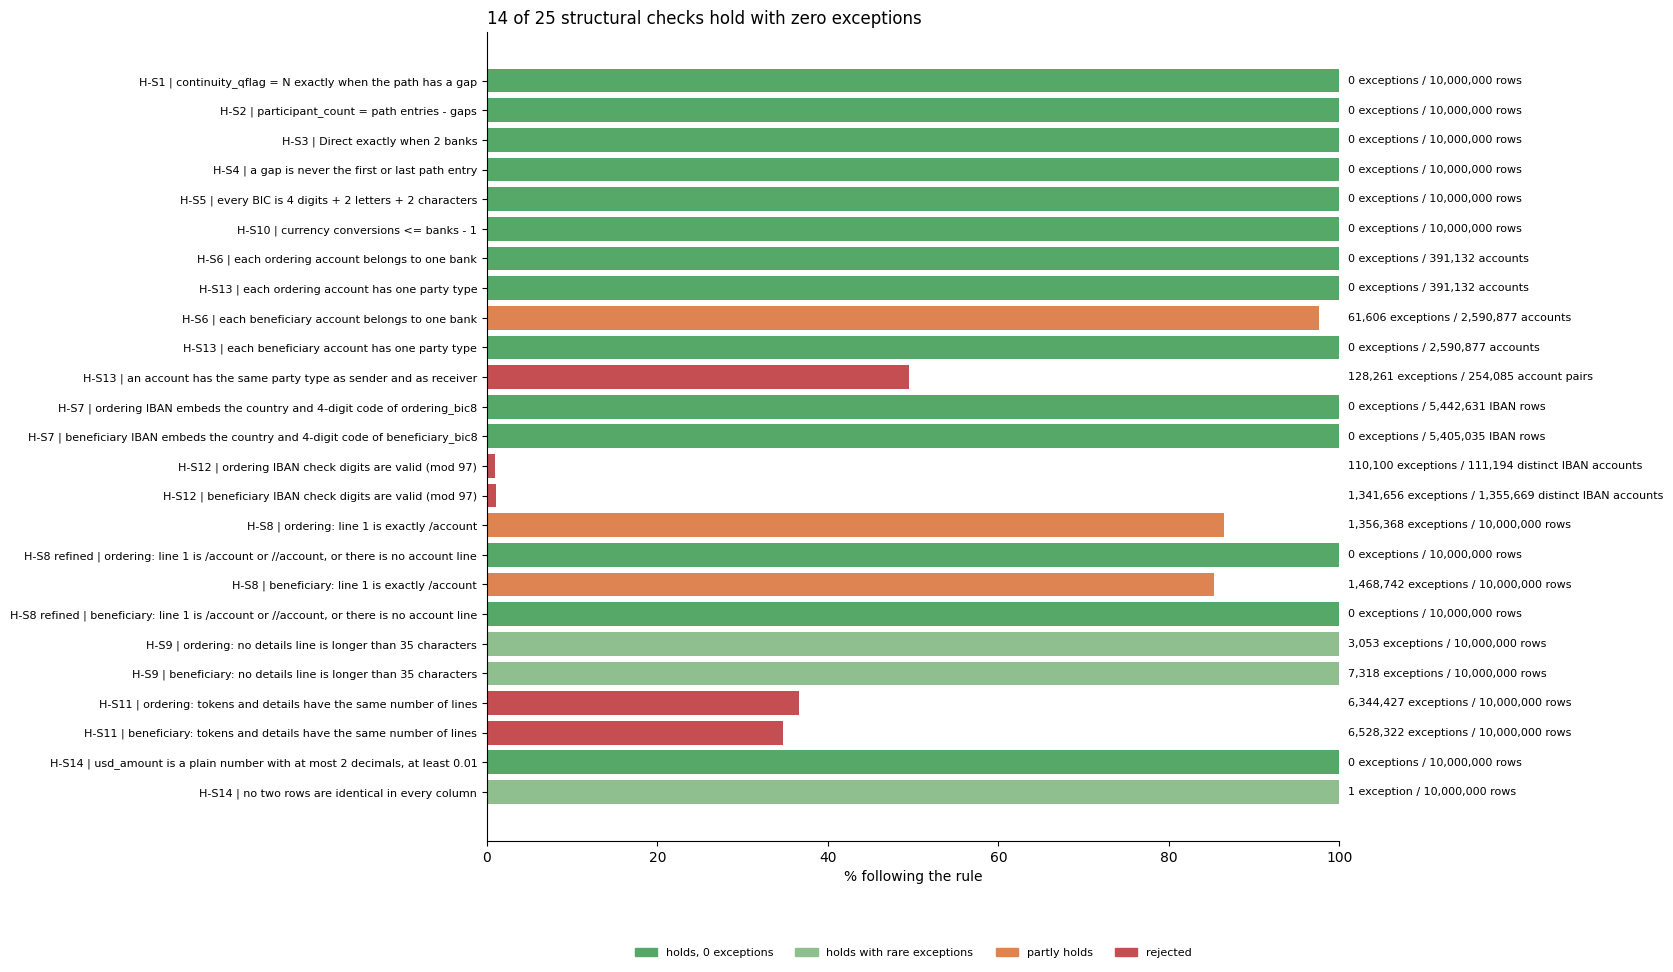

In [20]:
colors = {"holds, 0 exceptions": "#55A868", "holds with rare exceptions": "#8FBF8F",
          "partly holds": "#DD8452", "rejected": "#C44E52"}
plot = board.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 0.36 * len(plot) + 1.5))
ax.barh(range(len(plot)), plot.pct_following_rule, color=[colors[v] for v in plot.verdict])
ax.set_yticks(range(len(plot)))
ax.set_yticklabels([f"{r} | {s}" for r, s in zip(plot.rule, plot.statement)], fontsize=8)
for i, (pct, exc, tested, unit) in enumerate(zip(plot.pct_following_rule, plot.exceptions, plot.tested, plot.unit)):
    ax.text(101, i, f"{exc:,} exception{'' if exc == 1 else 's'} / {tested:,} {unit}", va="center", fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("% following the rule")
ax.spines[["top", "right"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=8)
ax.set_title(f"{(board.exceptions == 0).sum()} of {len(board)} structural checks hold with zero exceptions", loc="left")
eda.save(fig, "S3_consistency_scoreboard")
plt.show()

## 10. Results: reconstructed rules (all checked on 10,000,000 rows)

Every number below is printed by a cell above. "Sender" = ordering side, "receiver" = beneficiary side.

### Rules that hold with zero exceptions

| ID | Rule: condition → effect | Scope and size | Evidence | Confidence |
|---|---|---|---|---|
| R-S1 | Path contains at least one `...` → `continuity_qflag` = N; otherwise Y. The flag is computed from the path. | All rows. 767,204 rows (7.67%) have a gap, up to 6 gaps in one path. | Section 3 | Certain (0 exceptions) |
| R-S2 | `participant_count` = number of BICs in `bic8_path`; gaps are not counted. | All rows. 2 to 22 banks. | Section 3 | Certain (0 exceptions) |
| R-S3 | Exactly 2 banks → `Direct`. 3 or more banks → `Indirect` or `Covered`, never `Direct`. | All rows. Indirect has 3-22 banks, Covered 3-15. | Section 3 | Certain (0 exceptions). Does **not** say what separates Indirect from Covered. |
| R-S4 | A gap only ever sits between two known banks; the first and last path entries are always real BICs. | All rows. | Section 3 | Certain (0 exceptions) |
| R-S5 | Every BIC is 4 digits + 2-letter country + 2 characters, in both BIC columns and every path entry. | All rows, three columns. | Section 3 | Certain (0 exceptions) |
| R-S6 | `currency_conversion_count` is at most banks - 1 (one possible conversion per hand-off between two banks). | All rows. 78.65% of payments are exactly at the maximum. | Section 4, chart S1 | Certain (0 exceptions) |
| R-S7 | A sender account always belongs to the same bank and has the same party type. | 391,132 sender accounts. | Section 5 | Certain (0 exceptions) |
| R-S8 | An IBAN-shaped account is built from its bank: `_FAKE_` + bank's country (2 letters) + 2 digits + bank's 4-digit code + `00000000` + a 6-digit number. | 5,442,631 sender rows (54.43%) and 5,405,035 receiver rows (54.05%). | Section 6, chart S2 | Certain (0 exceptions) |
| R-S9 | The account line of the party details is `/account` or `//account`, copied character for character (spaces included), or it is left out. No other form exists. | All rows, both sides. Sender: 86.44% / 7.93% / 5.63%. Receiver: 85.31% / 8.59% / 6.09%. | Section 7 | Certain (0 exceptions) |
| R-S10 | `usd_amount` is written in whole cents and is never below 0.01; `total_duration` is whole seconds, never below 2. | All rows. | Section 8 | Certain (0 exceptions) |

### Rules that hold with measured exceptions

| ID | Rule | Size of the exception | Evidence | Confidence |
|---|---|---|---|---|
| R-S11 | Free-format detail lines are wrapped at 35 characters. | Rows with a longer line: 3,053 sender (0.03%), 7,318 receiver (0.07%). 10,366 of the 10,372 over-length lines are numbered lines (`1/` `2/` `3/`), which are not wrapped. | Section 7 | High. The 6 other lines are unexplained. |
| R-S12 | A receiver account in IBAN shape belongs to one bank (0 exceptions in 1,355,669 accounts). A receiver account in any other format is **not** unique to one bank. | 61,606 of 1,235,208 non-IBAN receiver accounts (4.99%) appear at 2 to 8 banks; they cover 588,770 payments. | Section 5 | High for the observation; the cause is open (see below). |

### Hypotheses that did not hold

- **H-S12, IBAN check digits are valid: rejected.** Only 0.98% (sender) and 1.03% (receiver) of distinct IBAN-shaped accounts pass the mod-97 test; 2 random digits would pass 1.03% of the time. The generator copies the *layout* of an IBAN but draws the check digits at random.
- **H-S13, an account keeps its party type on both sides: rejected.** Within one side the type never changes (0 exceptions in 391,132 sender and 2,590,877 receiver accounts). But of 254,085 account-and-bank pairs seen on both sides, the type differs in 50.48%; two independent draws would differ in 50.15%. The type is attached to the role in the payment, not to the account.
- **H-S6 for receivers: failed for non-IBAN accounts** (R-S12). We first suspected the 5% path-end noise. Ruled out: the path-end mismatch rate is 5.24% for the affected accounts against 4.96% for the others, and the payments of an affected account are split evenly between its banks (median share at the main bank: 0.50).
- **H-S8 as first written, line 1 is always `/account`: only partly.** It is true for 86.44% of sender rows and 85.31% of receiver rows; the refined rule R-S9 covers every row.
- **H-S11, tokens and details have the same number of lines: rejected.** The line counts differ in 63.44% of sender rows and 65.28% of receiver rows. Counting `<line_break>` tokens explains the difference in 77.34% and 75.66% of rows, not all.

### Found on the way (link to notebooks 02 and 09)

The IBAN agrees with the **BIC column** in 100% of rows, but with the **bank at the end of the path** in only 95.02% (sender, first bank) and 95.01% (receiver, last bank). The account is therefore always built from the party's bank. Notebook 09 shows that in those 5% of rows the path end is the bank the route was built for, and the party's bank is unrelated to it. Chart S2.

### What is still unexplained

1. Why non-IBAN receiver accounts appear at several banks while sender accounts never do (R-S12).
2. What decides between `/account`, `//account` and no account line. It is nearly independent of party type, except that sender consumers omit the line slightly more often (6.40% against 5.42% for businesses).
3. The exact rule linking `<line_break:N>` tokens to the lines of the details text.
4. The one fully identical pair of rows. Both are labelled `DUPLICATE_PAYMENT`, so we treat it as generated on purpose and removed nothing.

### What this may mean in the real world (interpretation, not observation)

- **R-S1, R-S2, R-S4:** a payment tracker only sees the legs that travel over its own network. A leg settled elsewhere (for example through a local clearing system) leaves a hole between two known banks. The flag and the count are bookkeeping on the visible route, which is why they never disagree with it.
- **R-S3:** `Direct` is the case where the sender's bank holds an account relationship with the receiver's bank; every other payment needs at least one intermediary (correspondent) bank.
- **R-S6:** a currency conversion happens when one bank passes the payment to the next in a different currency, so a chain of *k* banks offers *k - 1* opportunities.
- **R-S8:** a real IBAN is country code + 2 check digits + bank identifier + account number, so an account number reveals its bank. The dataset copies that layout. The random check digits (H-S12) are a place where the dataset departs from reality: real IBANs always pass the test.
- **R-S9, R-S11:** Swift payment messages carry party details as an optional account line starting with `/`, followed by lines of at most 35 characters; the numbered `1/` `2/` `3/` lines resemble the structured name / address / country format. This is general knowledge about the message format, not something the data can prove.
- **R-S12 (alternative explanations):** (a) outside the IBAN system an account number is only unique *within* a bank, so the same number can exist at two banks; (b) the receiver account is whatever the sender typed, so it is less controlled than the sender's own account. We prefer (a), because the payments are split evenly between the banks rather than concentrated on one with a few stray rows, but the data cannot settle it.

### What other dashboards can rely on

- Number of banks = `participant_count` = `path_entries - path_gaps`. Do not use `path_entries` alone.
- A **sender account** is a stable identity (one bank, one type). A **receiver account** that is not IBAN-shaped is not; use account + bank together to identify a receiver.
- The bank's country is characters 5-6 of the BIC, and it always matches the country inside an IBAN-shaped account.